In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

sns.set_style("whitegrid")
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)

RANDOM_STATE = 1234

## Load Data

In [ ]:
from pathlib import Path
import pandas as pd

def get_data_path(filename, subfolder='data'):
    """Return the full path to a data file relative to the project root."""
    try:
        current_dir = Path(__file__).resolve().parent
    except NameError:
        current_dir = Path.cwd()  # Jupyter / interactive fallback

    parent_dir = current_dir.parent
    return parent_dir / subfolder / filename


# Build the path
csv_path = get_data_path('Constructed Customer Dataset.csv')

# Load once
df = pd.read_csv(csv_path)

print(f"Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")

Shape: 55,245 rows, 18 columns


## First Look

In [10]:
display(df.head())

,customer_unique_id,recency,frequency,monetary,zip_code,city,state,total_items_volume,max_delivery_delay,is_delivered,is_approved,payment_method_count,primary_payment_type,max_installments,avg_satisfaction,min_review_score,total_reviews_given,label
0,0006fdc98a402fceb4eb0ee528f6a8d4,232,1,29.00,29400,mimoso do sul,ES,1,-12,1,1,1,credit_card,2,3.00,3,1,1
1,000c8bdb58a29e7115cfc257230fb21b,85,1,29.00,31555,belo horizonte,MG,1,-9,1,1,1,credit_card,2,5.00,5,1,1
2,001f3c4211216384d5fe59b041ce1461,353,1,35.84,8240,sao paulo,SP,1,-11,1,1,1,credit_card,3,3.00,3,1,1
3,002cdf87d4c03f08f7eb4551a923affc,127,1,228.67,13183,hortolandia,SP,1,14,1,1,1,credit_card,10,1.00,1,1,1
4,002d71b244beb91ca7030b15ab526446,289,1,130.56,18900,santa cruz do rio pardo,SP,1,-12,1,1,1,boleto,1,5.00,5,1,1


In [11]:
display(df.tail())

,customer_unique_id,recency,frequency,monetary,zip_code,city,state,total_items_volume,max_delivery_delay,is_delivered,is_approved,payment_method_count,primary_payment_type,max_installments,avg_satisfaction,min_review_score,total_reviews_given,label
55240,ffcda3a0829ba6d3a02cd280e29b19a6,60,1,111.40,13870,sao joao da boa vista,SP,1,-15,1,1,1,credit_card,2,5.00,5,1,1
55241,ffd8073f8abebb72f6afe32e8f8d7827,50,1,103.33,39400,montes claros,MG,1,-24,1,1,1,credit_card,3,2.00,2,1,1
55242,ffe8f2fc0cee48f79934bd2c506fafc0,217,1,111.42,8215,sao paulo,SP,1,-14,1,1,1,boleto,1,3.00,3,1,1
55243,ffedff0547d809c90c05c2691c51f9b7,342,1,32.42,14091,ribeirao preto,SP,1,-30,1,1,1,credit_card,3,5.00,5,1,1
55244,fff1bdd5c5e37ca79dd74deeb91aa5b6,11,1,172.98,77824,araguaina,TO,1,30,1,1,1,debit_card,1,1.00,1,1,1


In [12]:
display(df.sample(5, random_state=1234))

,customer_unique_id,recency,frequency,monetary,zip_code,city,state,total_items_volume,max_delivery_delay,is_delivered,is_approved,payment_method_count,primary_payment_type,max_installments,avg_satisfaction,min_review_score,total_reviews_given,label
48553,6b52d3725aa7cca24203308be666308b,332,1,97.20,20785,rio de janeiro,RJ,1,31,0,1,1,credit_card,9,1.00,1,1,1
50851,9dfef33f5812f001155860c7878690f4,131,1,452.00,81570,curitiba,PR,1,-30,1,1,1,credit_card,8,5.00,5,1,1
18091,a971c038c92add1b756e2f089ad8f180,287,1,26.60,31255,belo horizonte,MG,1,-14,1,1,1,credit_card,1,3.00,3,1,1
46407,3acca5ead7853e20f34528166fbbfede,256,1,51.59,94480,viamao,RS,1,-12,1,1,1,credit_card,3,5.00,5,1,1
27724,8a69f55fdbcc10ee37921333398f0ee9,27,1,109.41,13484,limeira,SP,1,-8,1,1,1,boleto,1,4.00,4,1,1


In [13]:
df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 55245 entries, 0 to 55244
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_unique_id    55245 non-null  str    
 1   recency               55245 non-null  int64  
 2   frequency             55245 non-null  int64  
 3   monetary              55245 non-null  float64
 4   zip_code              55245 non-null  int64  
 5   city                  55245 non-null  str    
 6   state                 55245 non-null  str    
 7   total_items_volume    55245 non-null  int64  
 8   max_delivery_delay    55245 non-null  int64  
 9   is_delivered          55245 non-null  int64  
 10  is_approved           55245 non-null  int64  
 11  payment_method_count  55245 non-null  int64  
 12  primary_payment_type  55245 non-null  str    
 13  max_installments      55245 non-null  int64  
 14  avg_satisfaction      55245 non-null  float64
 15  min_review_score      55245 no

## Column Overview

In [14]:
summary = pd.DataFrame({
    'dtype': df.dtypes,
    'non_null': df.notnull().sum(),
    'null': df.isnull().sum(),
    'null_pct': (df.isnull().mean() * 100).round(2),
    'n_unique': df.nunique(),
    'sample': [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns]
}).sort_values('null_pct', ascending=False)

display(summary)

,dtype,non_null,null,null_pct,n_unique,sample
customer_unique_id,str,55245,0,0.00,55245,0006fdc98a402fceb4eb0ee528f6a8d4
recency,int64,55245,0,0.00,366,232
frequency,int64,55245,0,0.00,8,1
monetary,float64,55245,0,0.00,18339,29.00
zip_code,int64,55245,0,0.00,13131,29400
city,str,55245,0,0.00,3542,mimoso do sul
state,str,55245,0,0.00,27,ES
total_items_volume,int64,55245,0,0.00,17,1
max_delivery_delay,int64,55245,0,0.00,62,-12
is_delivered,int64,55245,0,0.00,2,1


## Split Column Types

In [16]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include=['str', 'category']).columns.tolist()
bool_cols = df.select_dtypes(include='bool').columns.tolist()
dt_cols = df.select_dtypes(include='datetime').columns.tolist()

print(f"Numeric    ({len(num_cols)}): {num_cols}")
print(f"Categorical({len(cat_cols)}): {cat_cols}")
print(f"Boolean    ({len(bool_cols)}): {bool_cols}")
print(f"Datetime   ({len(dt_cols)}): {dt_cols}")

Numeric    (14): ['recency', 'frequency', 'monetary', 'zip_code', 'total_items_volume', 'max_delivery_delay', 'is_delivered', 'is_approved', 'payment_method_count', 'max_installments', 'avg_satisfaction', 'min_review_score', 'total_reviews_given', 'label']
Categorical(4): ['customer_unique_id', 'city', 'state', 'primary_payment_type']
Boolean    (0): []
Datetime   (0): []


## Missing Values

In [17]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing):
    miss_df = pd.DataFrame({
        'count': missing,
        'pct': (missing / len(df) * 100).round(2)
    })
    display(miss_df)

    plt.figure(figsize=(10, max(3, len(missing)*0.3)))
    sns.barplot(x=miss_df['pct'], y=miss_df.index, palette='Reds_r')
    plt.title('Missing Values (%)')
    plt.xlabel('% missing')
    plt.tight_layout()
    plt.show()
else:
    print("✅ No missing values")

✅ No missing values


## Missingness Pattern

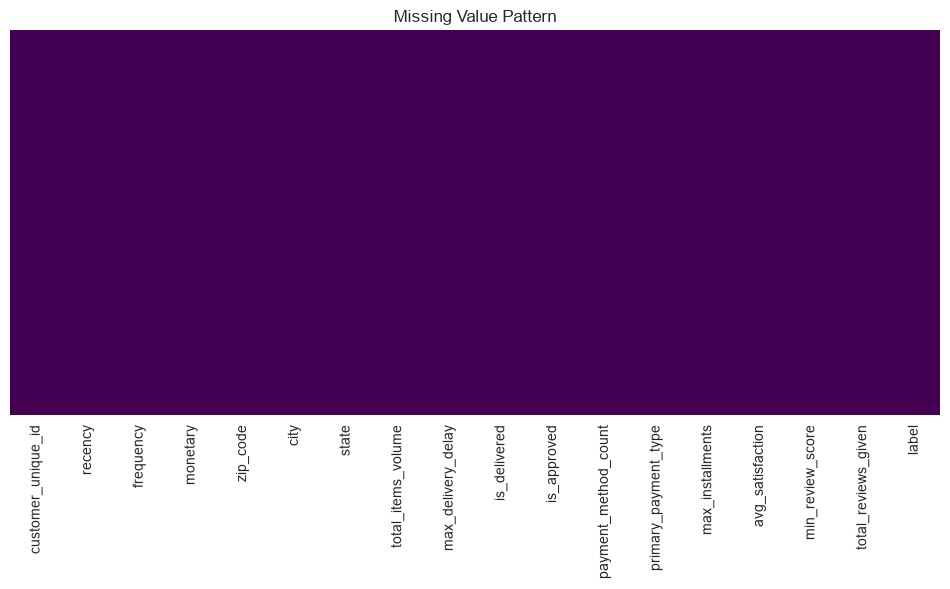

In [18]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Value Pattern')
plt.show()

## Duplicates

In [19]:
dup_count = df.duplicated().sum()
print(f"Fully duplicated rows: {dup_count} ({dup_count/len(df)*100:.2f}%)")

Fully duplicated rows: 0 (0.00%)


## Constant / Near-Constant Columns

In [20]:
for col in df.columns:
    top_freq = df[col].value_counts(normalize=True, dropna=False).iloc[0]
    if top_freq > 0.95:
        print(f"⚠️  {col}: {top_freq*100:.2f}% single value")

⚠️  frequency: 97.08% single value
⚠️  is_delivered: 97.70% single value
⚠️  is_approved: 100.00% single value
⚠️  payment_method_count: 96.77% single value
⚠️  total_reviews_given: 96.18% single value
⚠️  label: 98.82% single value


## Categorical Cardinality

In [21]:
for col in cat_cols:
    n = df[col].nunique()
    flag = "⚠️ HIGH" if n > 50 else ""
    print(f"{col}: {n} unique {flag}")

customer_unique_id: 55245 unique ⚠️ HIGH
city: 3542 unique ⚠️ HIGH
state: 27 unique 
primary_payment_type: 4 unique 


## Numeric Summary

In [22]:
display(df[num_cols].describe().T.assign(
    skew=df[num_cols].skew(),
    kurtosis=df[num_cols].kurtosis(),
    missing_pct=(df[num_cols].isnull().mean()*100).round(2)
))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,missing_pct
recency,"55,245.00",146.72,101.07,0.00,59.00,124.00,226.00,365.00,0.44,-0.94,0.00
frequency,"55,245.00",1.03,0.20,1.00,1.00,1.00,1.00,9.00,9.38,169.60,0.00
monetary,"55,245.00",162.62,220.16,10.07,62.78,106.29,180.61,"13,664.08",10.45,344.79,0.00
zip_code,"55,245.00","36,164.66","29,872.14","1,004.00","12,225.00","26,033.00","60,541.00","99,990.00",0.73,-0.86,0.00
total_items_volume,"55,245.00",1.18,0.61,1.00,1.00,1.00,1.00,21.00,7.44,115.73,0.00
max_delivery_delay,"55,245.00",-10.21,10.76,-30.00,-16.00,-12.00,-7.00,31.00,1.87,4.91,0.00
is_delivered,"55,245.00",0.98,0.15,0.00,1.00,1.00,1.00,1.00,-6.37,38.56,0.00
is_approved,"55,245.00",1.00,0.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00
payment_method_count,"55,245.00",1.05,0.42,1.00,1.00,1.00,1.00,29.00,25.71,"1,104.50",0.00
max_installments,"55,245.00",3.01,2.78,1.00,1.00,2.00,4.00,24.00,1.59,2.49,0.00


## Numeric Distributions (Histograms)

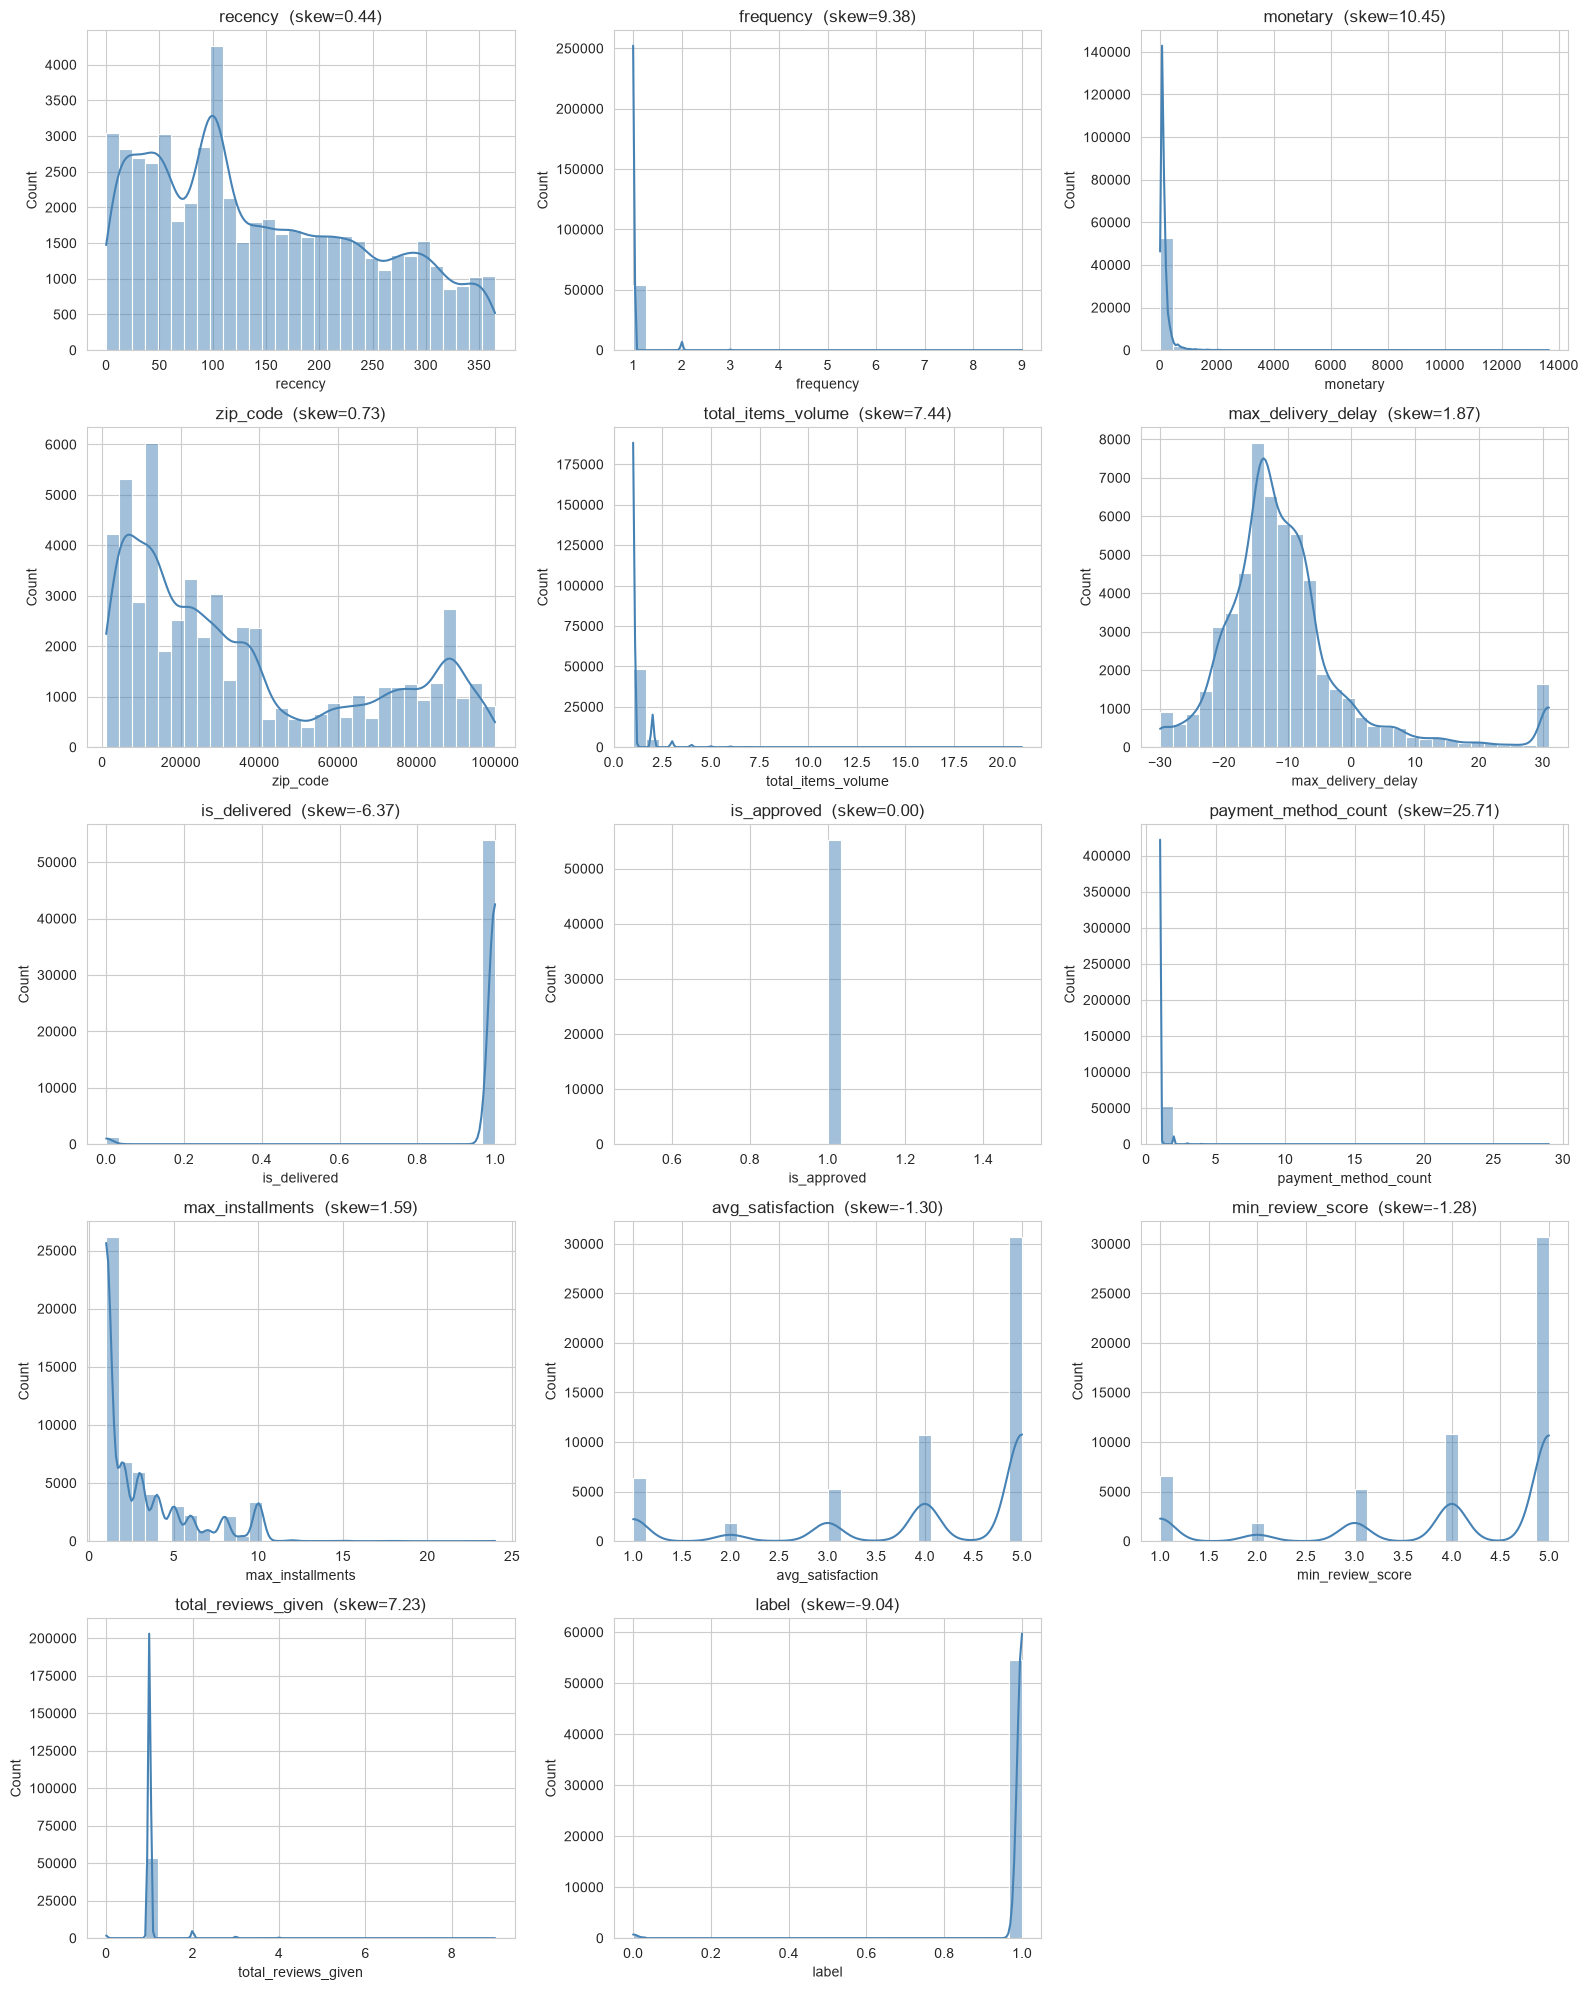

In [23]:
n = len(num_cols)
rows = (n + 2) // 3

fig, axes = plt.subplots(rows, 3, figsize=(16, 4*rows))
axes = np.array(axes).flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], bins=30, color='steelblue')
    axes[i].set_title(f'{col}  (skew={df[col].skew():.2f})')

for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## Numeric Boxplots (Outlier Visual)

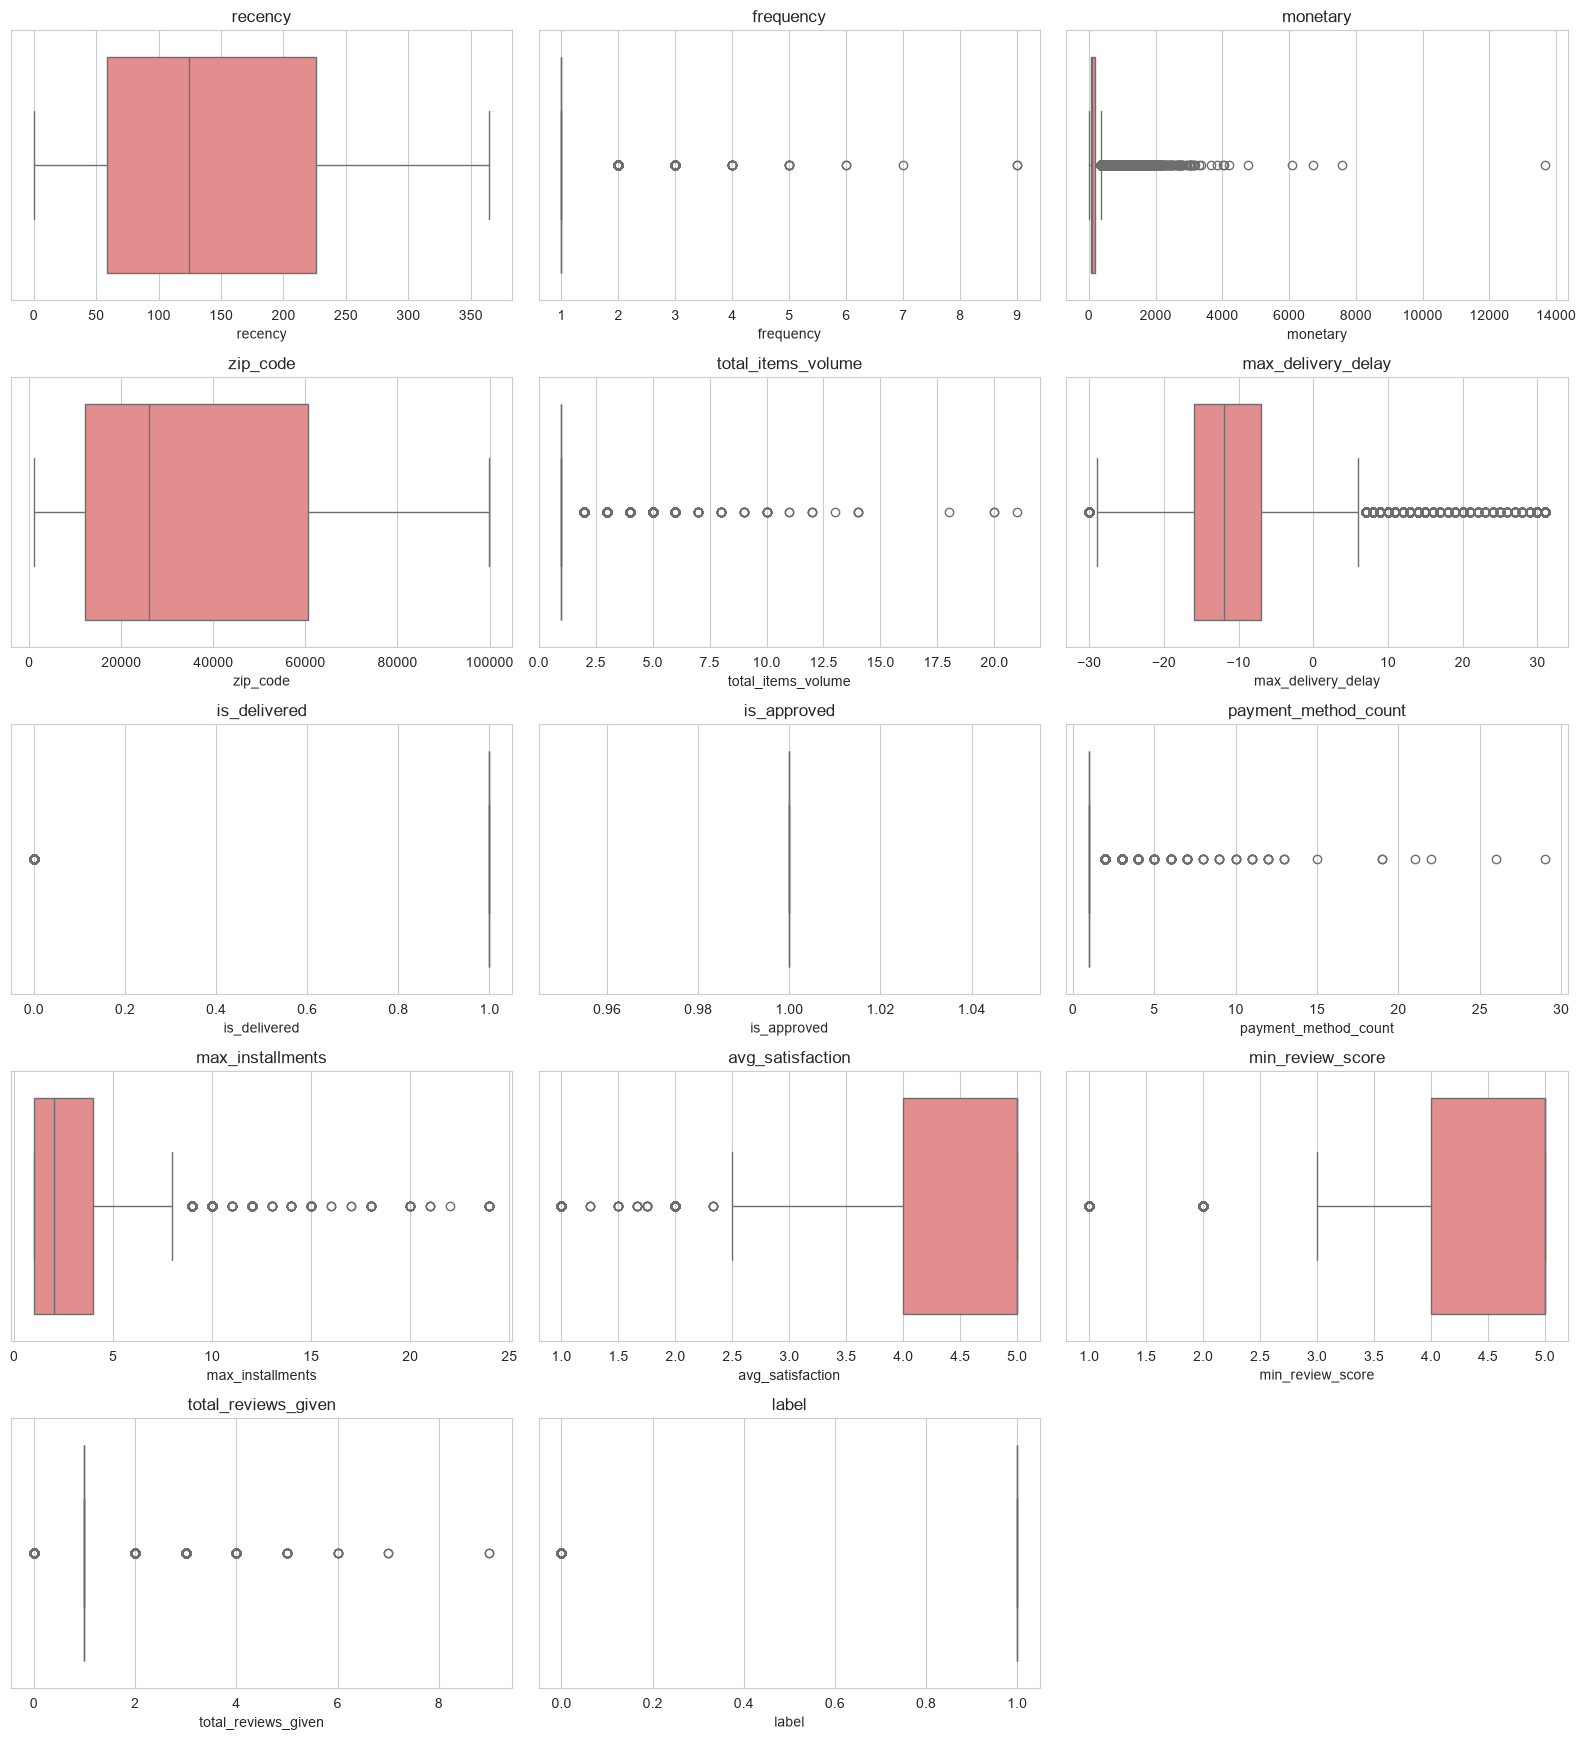

In [24]:
fig, axes = plt.subplots(rows, 3, figsize=(16, 3.5*rows))
axes = np.array(axes).flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col].dropna(), ax=axes[i], color='lightcoral')
    axes[i].set_title(col)

for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## Categorical Distributions

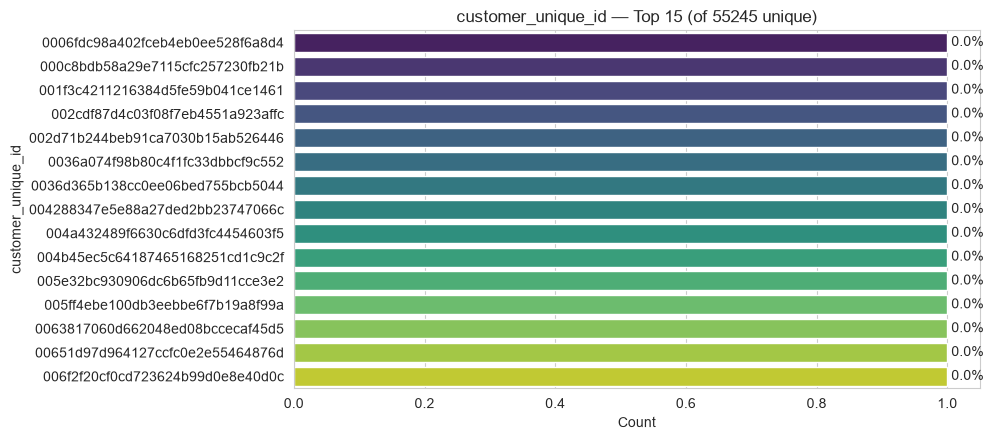

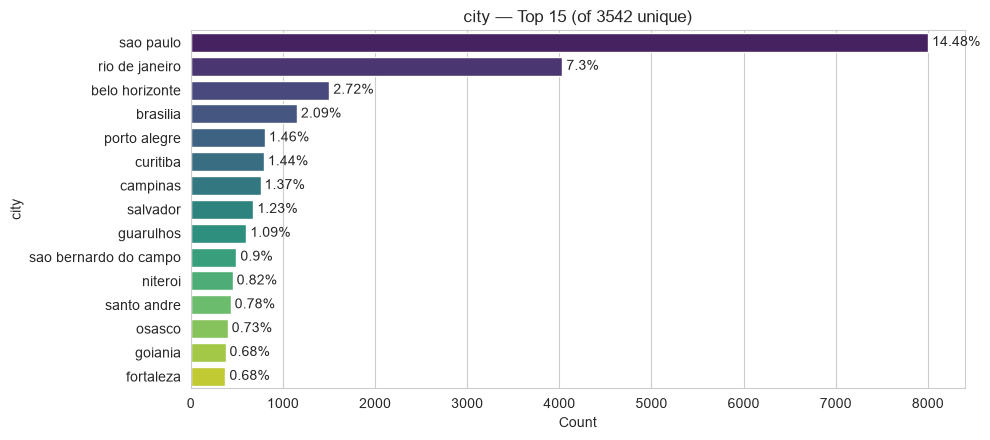

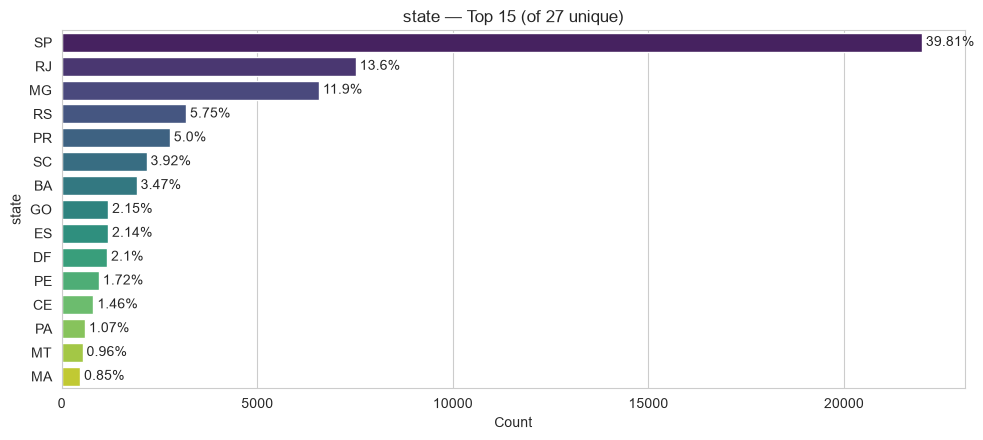

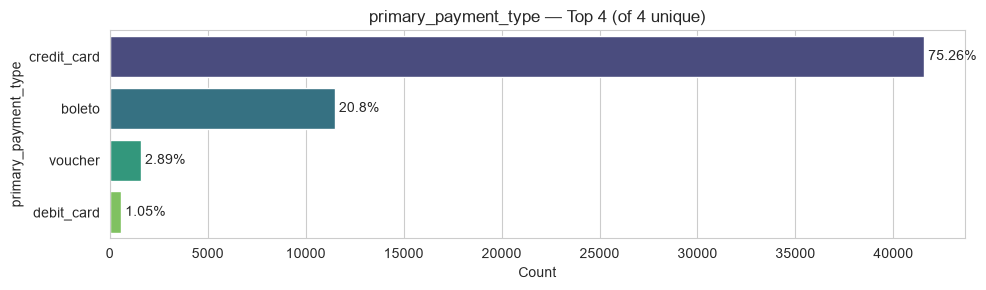

In [ ]:
for col in cat_cols:
    vc = df[col].value_counts().head(15)
    pct = (vc / len(df) * 100).round(2)

    fig, ax = plt.subplots(figsize=(10, max(3, len(vc)*0.3)))
    sns.barplot(
        x=vc.values,
        y=vc.index,          
        hue=vc.index,        
        palette='viridis',
        legend=False,
        ax=ax
    )
    for i, (v, p) in enumerate(zip(vc.values, pct.values)):
        ax.text(v, i, f' {p}%', va='center')
    ax.set_title(f'{col} — Top {len(vc)} (of {df[col].nunique()} unique)')
    ax.set_xlabel('Count')
    plt.tight_layout()
    plt.show()

## Outlier Detection

In [30]:
outlier_report = []
for col in num_cols:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((s < lower) | (s > upper)).sum()
    outlier_report.append({
        'column': col, 'q1': q1, 'q3': q3, 'iqr': iqr,
        'lower': lower, 'upper': upper,
        'outliers': n_out,
        'pct': round(n_out/len(s)*100, 2)
    })

display(pd.DataFrame(outlier_report).set_index('column').sort_values('pct', ascending=False))


,q1,q3,iqr,lower,upper,outliers,pct
column,,,,,,,
min_review_score,4.00,5.00,1.00,2.50,6.50,8400,15.20
avg_satisfaction,4.00,5.00,1.00,2.50,6.50,8185,14.82
total_items_volume,1.00,1.00,0.00,1.00,1.00,6813,12.33
monetary,62.78,180.61,117.83,-113.97,357.36,4386,7.94
max_delivery_delay,-16.00,-7.00,9.00,-29.50,6.50,4108,7.44
max_installments,1.00,4.00,3.00,-3.50,8.50,3947,7.14
total_reviews_given,1.00,1.00,0.00,1.00,1.00,2112,3.82
payment_method_count,1.00,1.00,0.00,1.00,1.00,1786,3.23
frequency,1.00,1.00,0.00,1.00,1.00,1614,2.92


## Outlier Detectiom (Z-score)

In [31]:
z = np.abs(stats.zscore(df[num_cols].dropna(), nan_policy='omit'))
counts = (z > 3).sum(axis=0)
for col, c in zip(num_cols, counts):
    print(f"{col}: {c} ({c/len(df)*100:.2f}%)")

recency: 0 (0.00%)
frequency: 1614 (2.92%)
monetary: 931 (1.69%)
zip_code: 0 (0.00%)
total_items_volume: 1624 (2.94%)
max_delivery_delay: 1815 (3.29%)
is_delivered: 1269 (2.30%)
is_approved: 0 (0.00%)
payment_method_count: 345 (0.62%)
max_installments: 185 (0.33%)
avg_satisfaction: 0 (0.00%)
min_review_score: 0 (0.00%)
total_reviews_given: 2112 (3.82%)
label: 652 (1.18%)


C:\Users\DELL\AppData\Local\Temp\ipykernel_20040\1237814274.py:1: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  z = np.abs(stats.zscore(df[num_cols].dropna(), nan_policy='omit'))


## Correlation Matrix

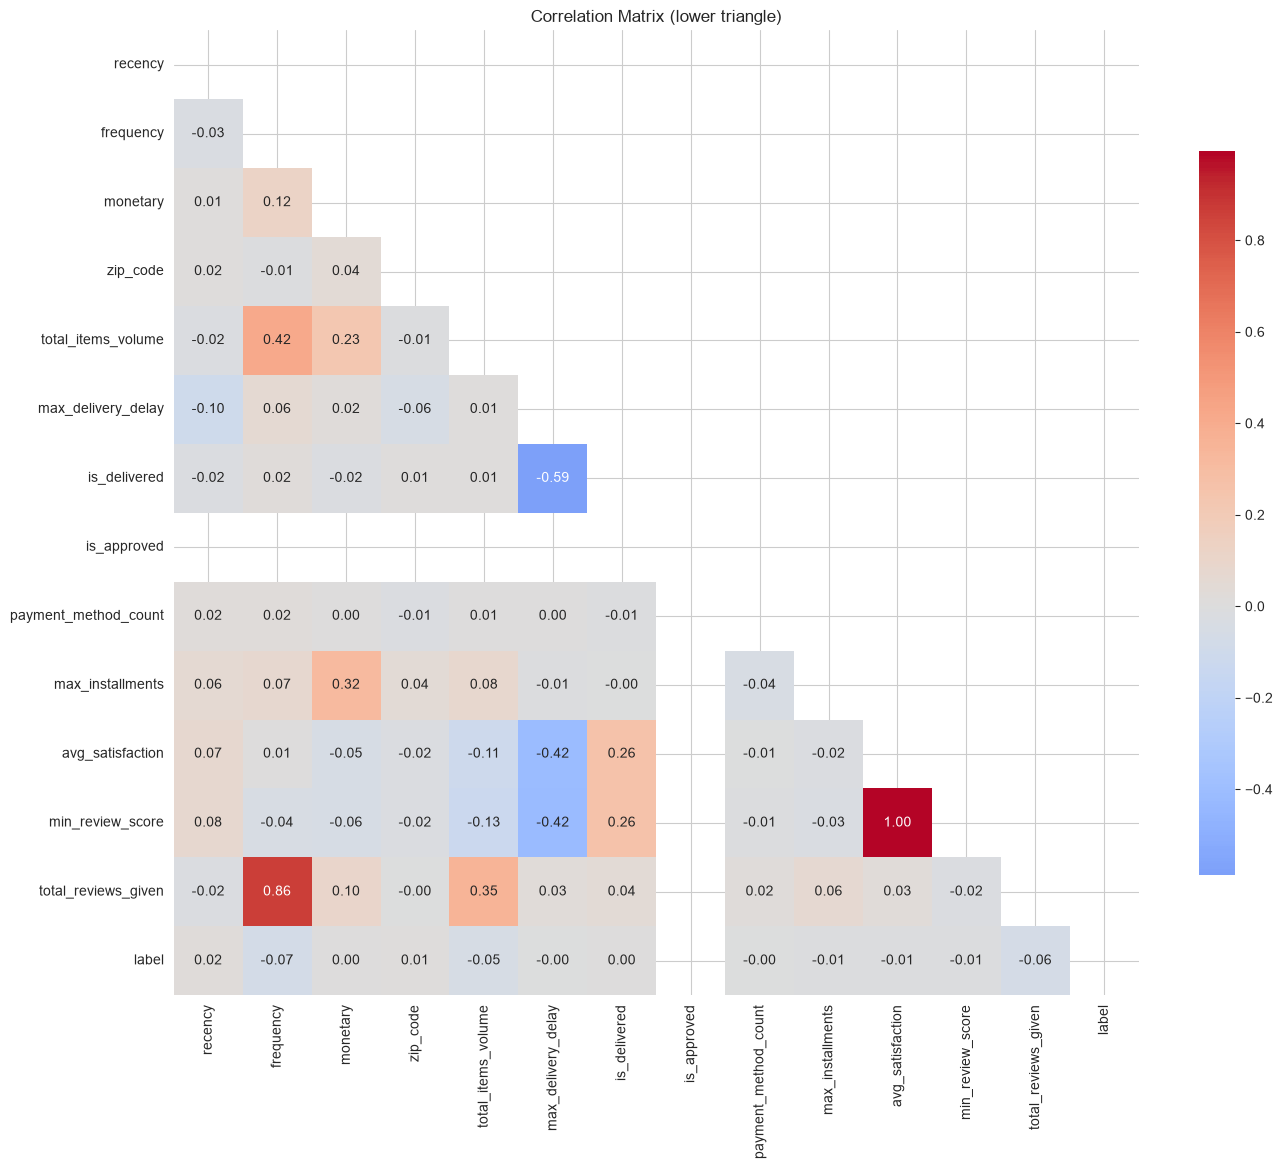

In [32]:
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(min(14, len(num_cols)+4), min(12, len(num_cols)+3)))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=len(num_cols) <= 15, fmt='.2f',
            cmap='coolwarm', center=0, square=True, ax=ax,
            cbar_kws={'shrink': 0.7})
ax.set_title('Correlation Matrix (lower triangle)')
plt.tight_layout()
plt.show()

## Highly correlated pairs

In [33]:
pairs = (corr.abs()
         .where(np.triu(np.ones(corr.shape), k=1).astype(bool))
         .stack()
         .sort_values(ascending=False))

print("Top correlated pairs:")
display(pairs.head(15))
print("\nPairs with |r| > 0.7:")
display(pairs[pairs > 0.7])

Top correlated pairs:


avg_satisfaction    min_review_score      1.00
frequency           total_reviews_given   0.86
max_delivery_delay  is_delivered          0.59
                    min_review_score      0.42
                    avg_satisfaction      0.42
frequency           total_items_volume    0.42
total_items_volume  total_reviews_given   0.35
monetary            max_installments      0.32
is_delivered        avg_satisfaction      0.26
                    min_review_score      0.26
monetary            total_items_volume    0.23
total_items_volume  min_review_score      0.13
frequency           monetary              0.12
total_items_volume  avg_satisfaction      0.11
recency             max_delivery_delay    0.10
dtype: float64


Pairs with |r| > 0.7:


avg_satisfaction  min_review_score      1.00
frequency         total_reviews_given   0.86
dtype: float64

## Pairplot (Numeric vs Numeric)

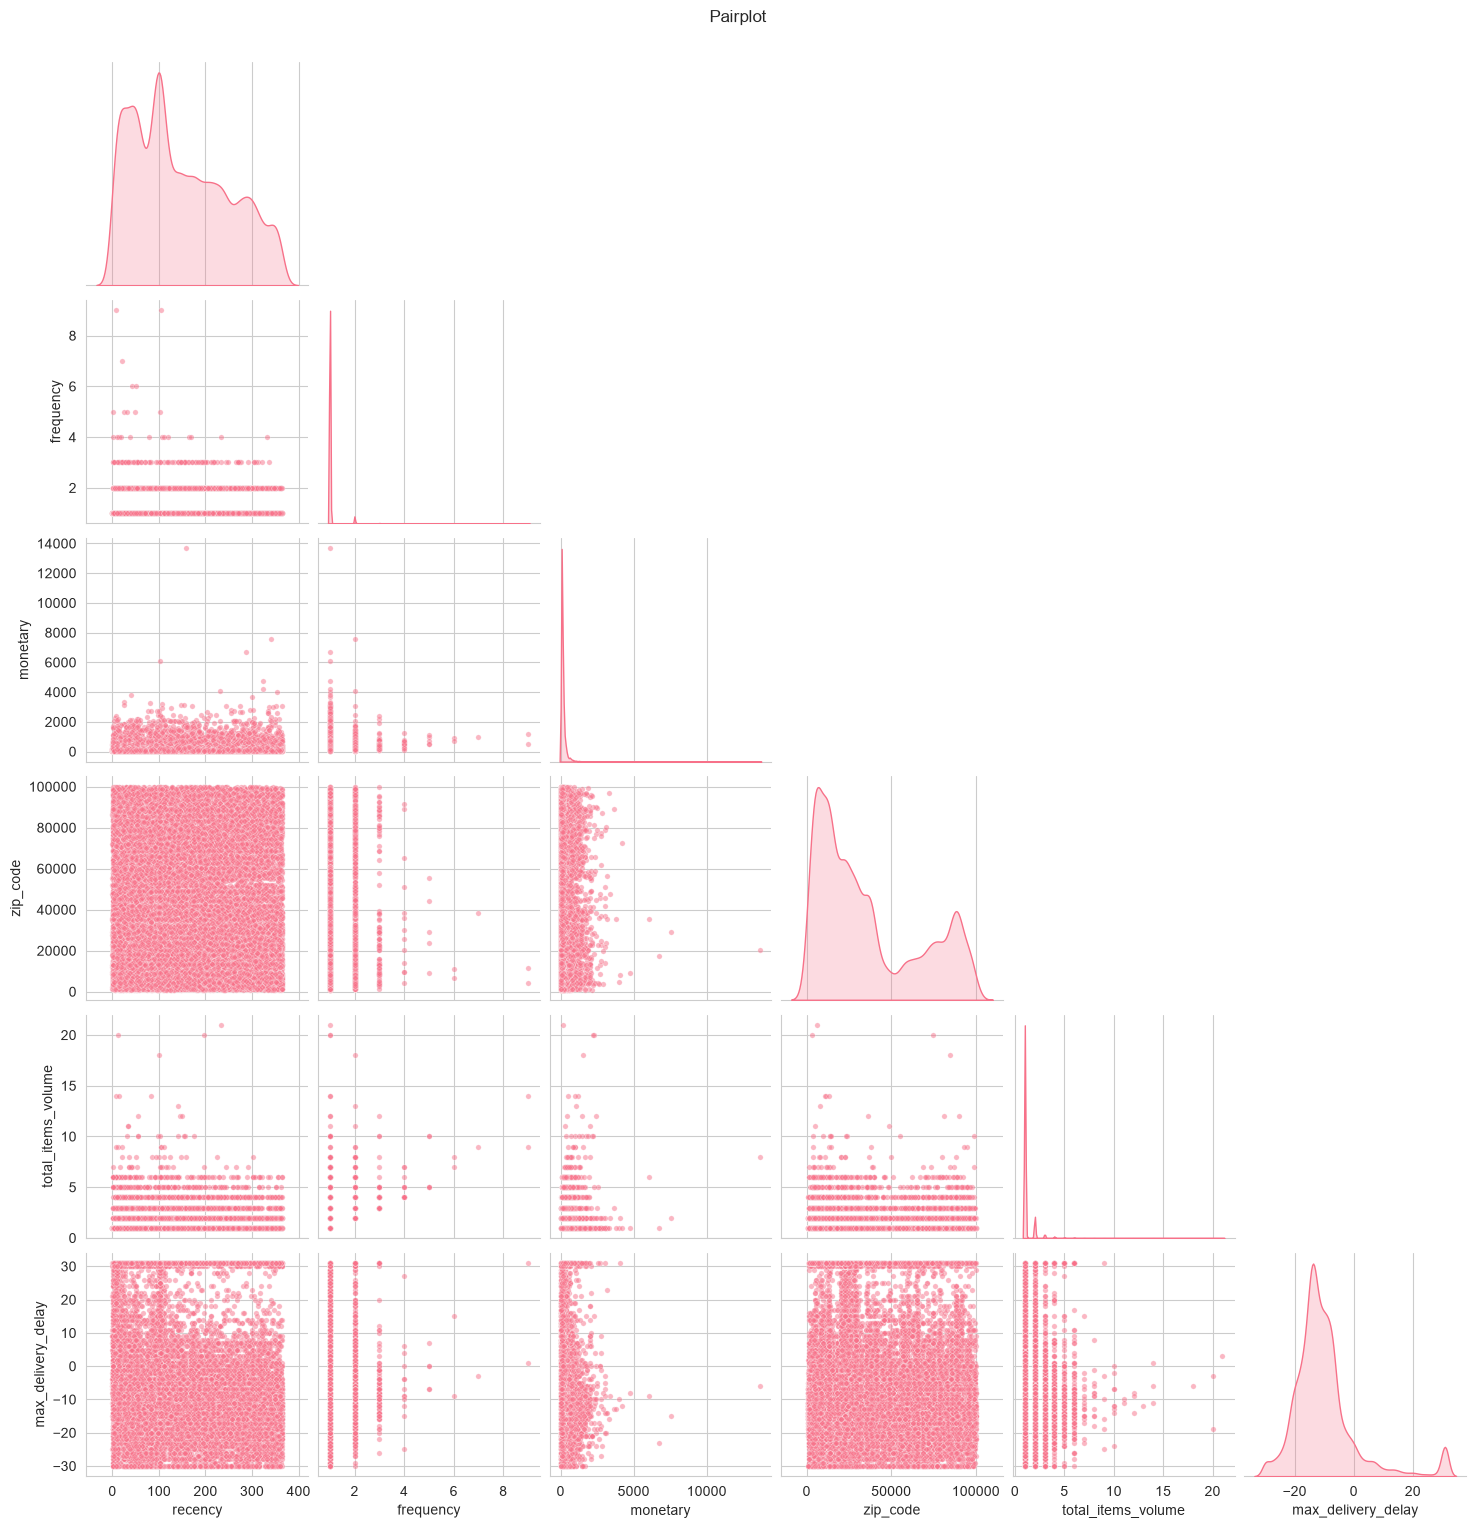

In [34]:
cols_for_pair = num_cols[:6]
sns.pairplot(df[cols_for_pair].dropna(), diag_kind='kde', corner=True,
             plot_kws={'alpha': 0.5, 's': 15})
plt.suptitle('Pairplot', y=1.02)
plt.show()

## Categorical vs Numeric(Boxplots)

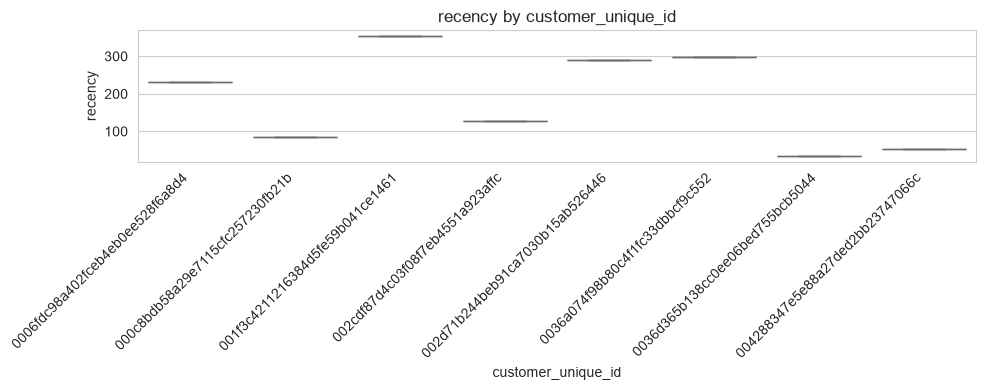

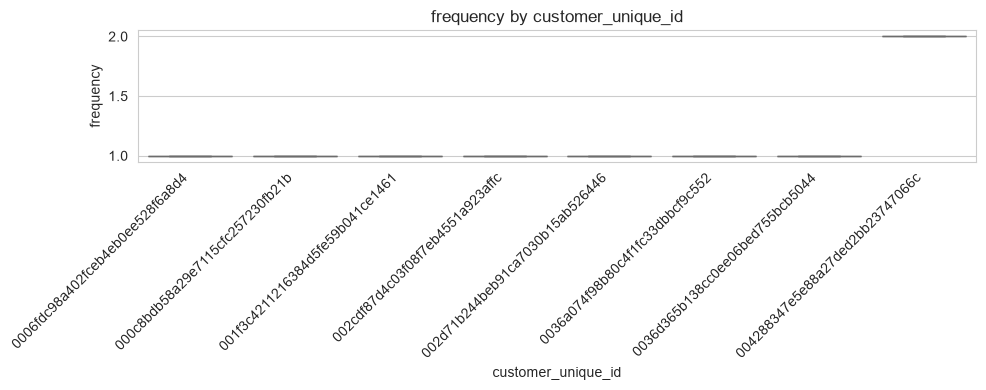

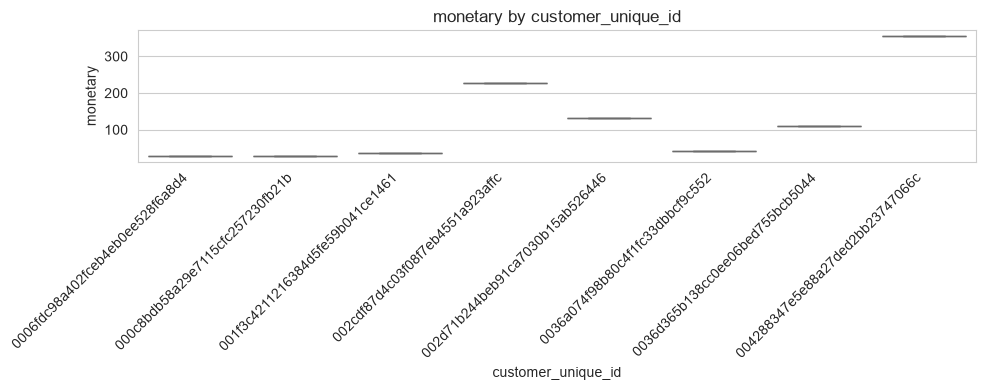

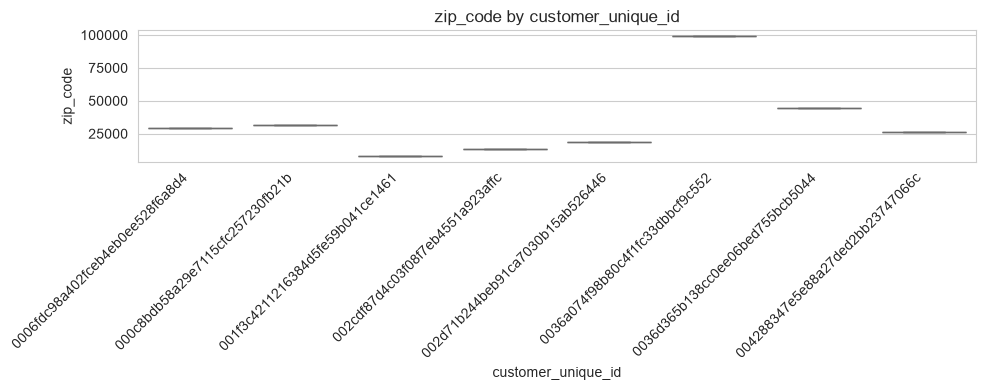

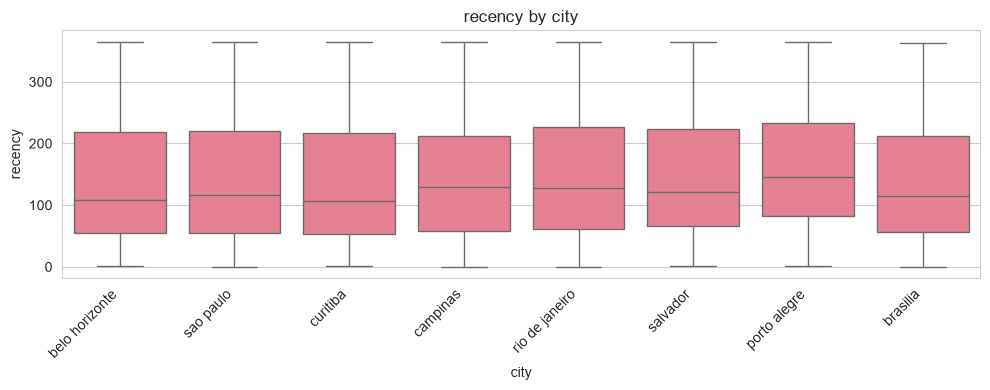

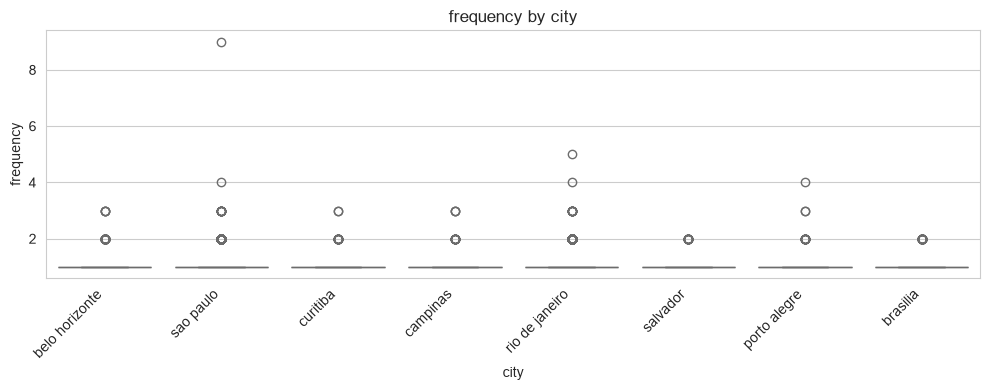

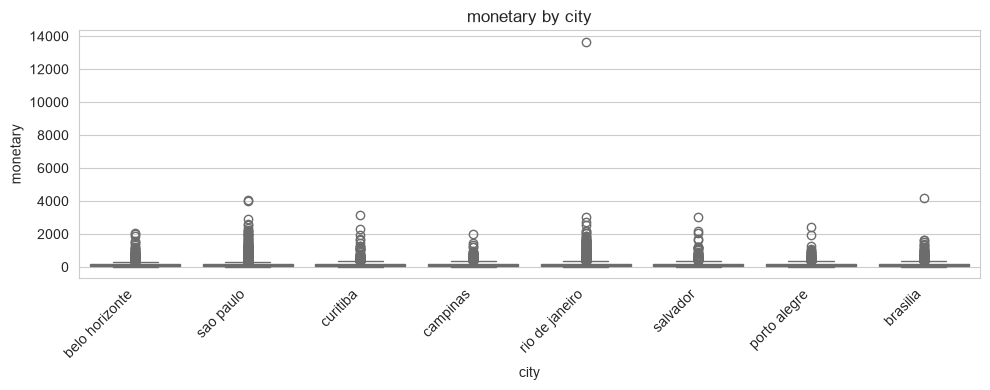

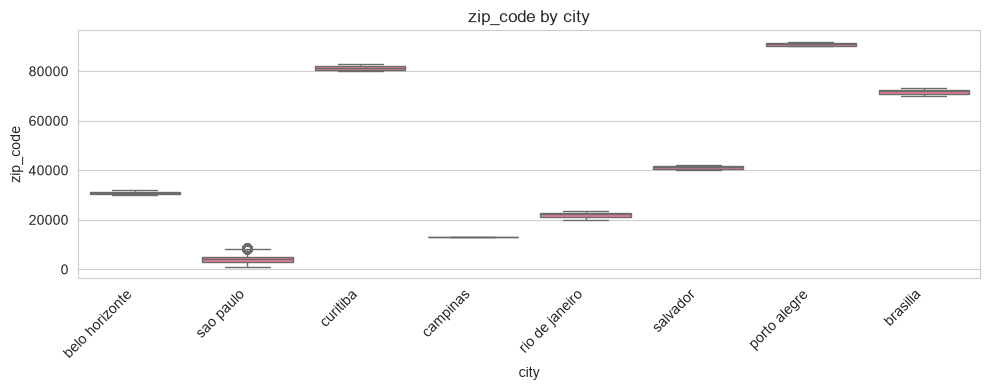

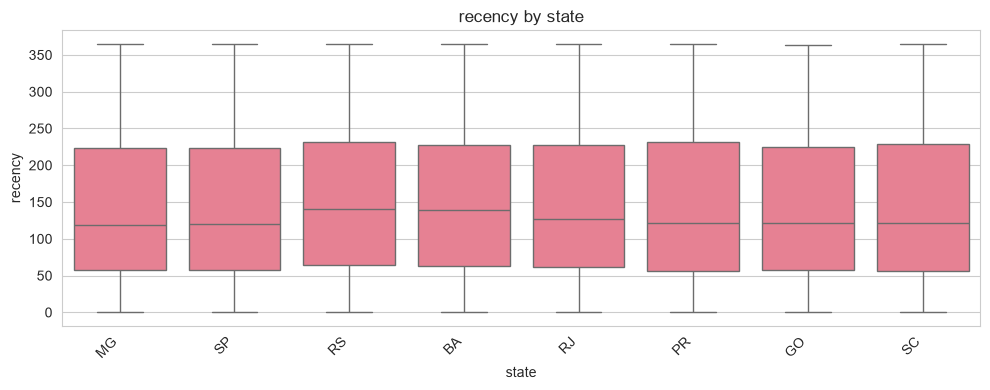

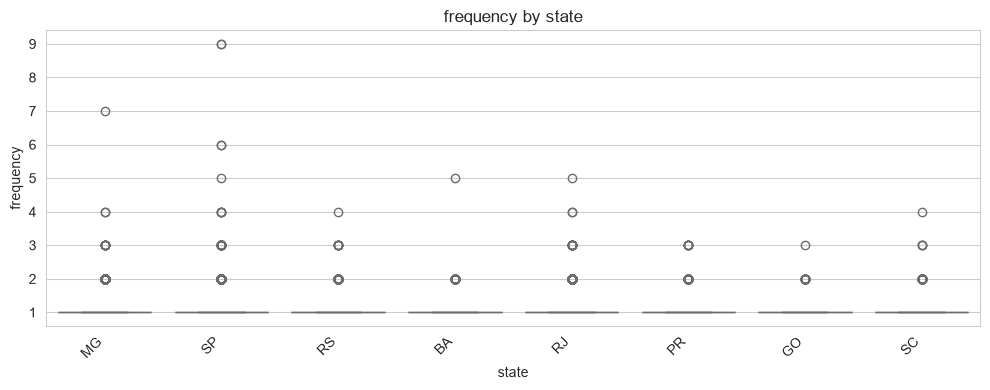

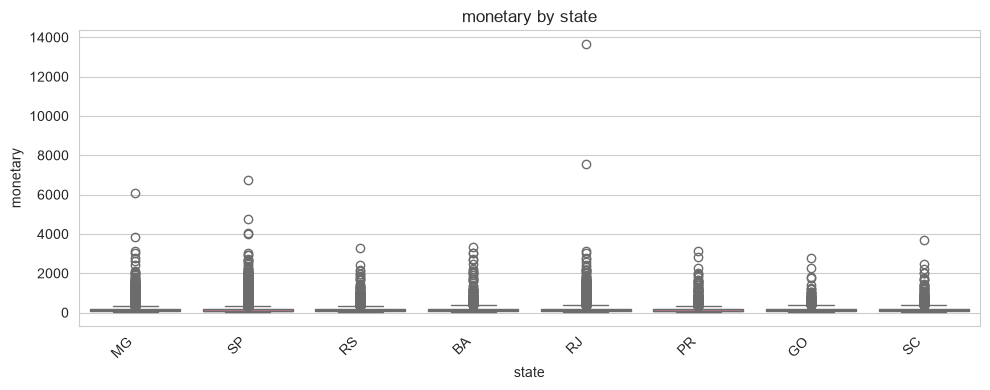

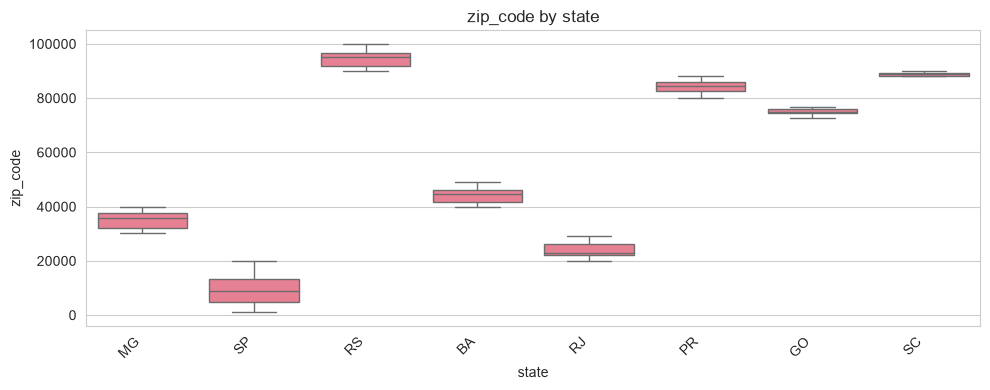

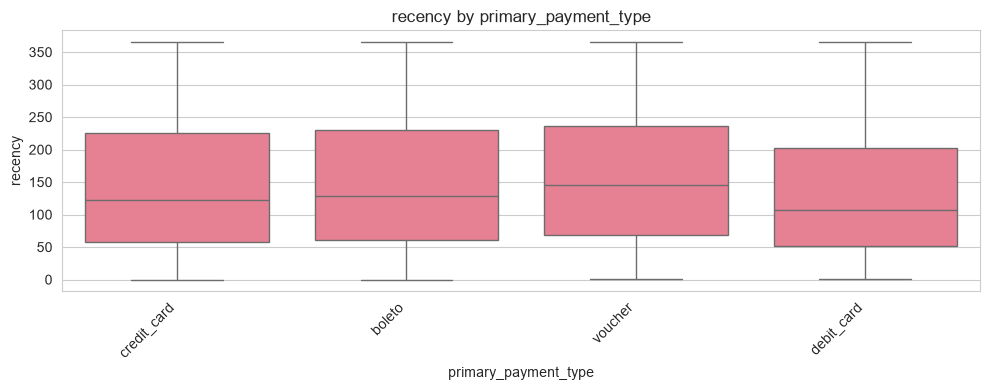

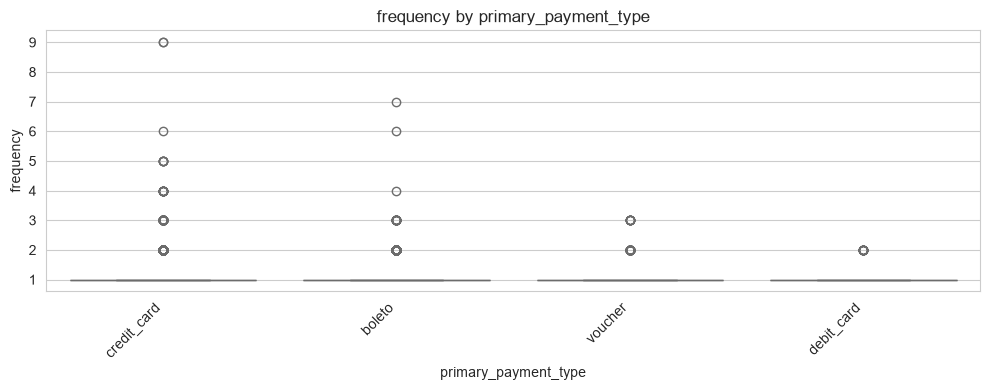

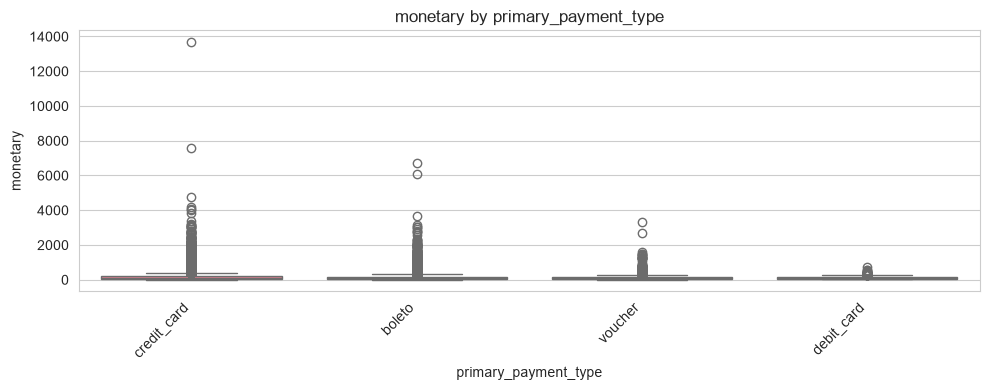

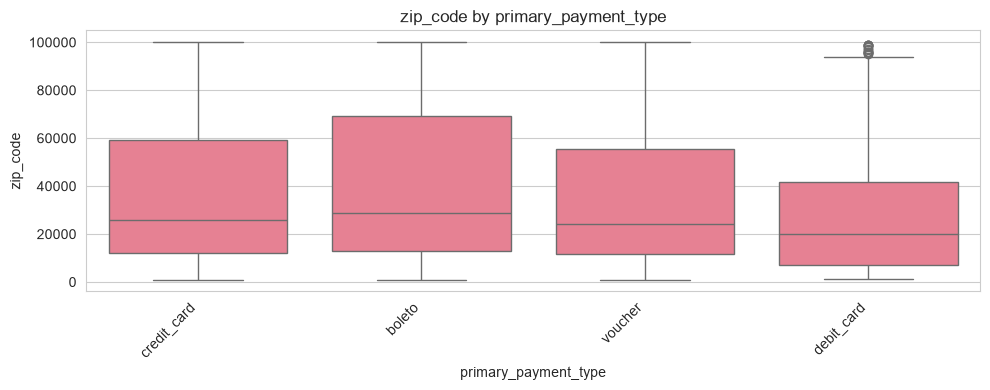

In [35]:
for cat in cat_cols[:5]:
    if df[cat].nunique() > 8:
        top = df[cat].value_counts().head(8).index
        sub = df[df[cat].isin(top)]
    else:
        sub = df

    for num in num_cols[:4]:
        plt.figure(figsize=(10, 4))
        sns.boxplot(data=sub, x=cat, y=num)
        plt.xticks(rotation=45, ha='right')
        plt.title(f'{num} by {cat}')
        plt.tight_layout()
        plt.show()

## Categorical vs Categorical

In [38]:
for i, c1 in enumerate(cat_cols):
    for c2 in cat_cols[i+1:]:
        if df[c1].nunique() <= 10 and df[c2].nunique() <= 10:
            ct = pd.crosstab(df[c1], df[c2], normalize='index') * 100
            plt.figure(figsize=(8, 5))
            sns.heatmap(ct, annot=True, fmt='.1f', cmap='Blues')
            plt.title(f'{c2} distribution within {c1} (%)')
            plt.tight_layout()
            plt.show()
        else:
            "Nothing to show"

## Target Analysis

label
1    54593
0      652
Name: count, dtype: int64

Imbalance ratio: 83.73


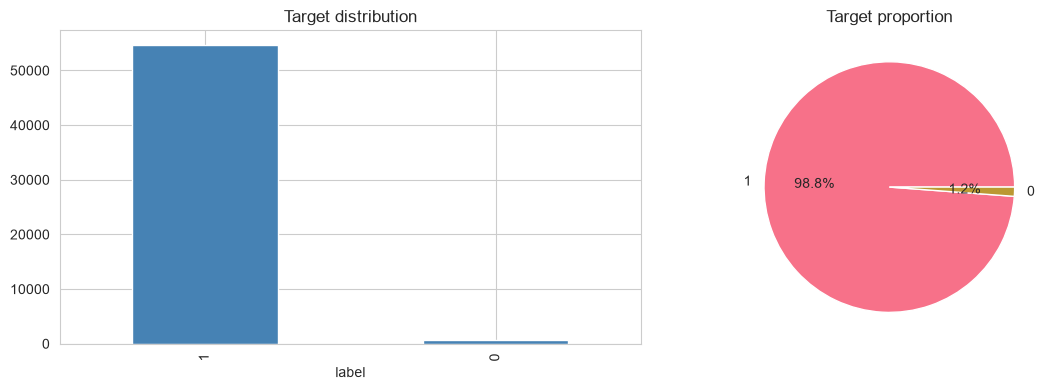

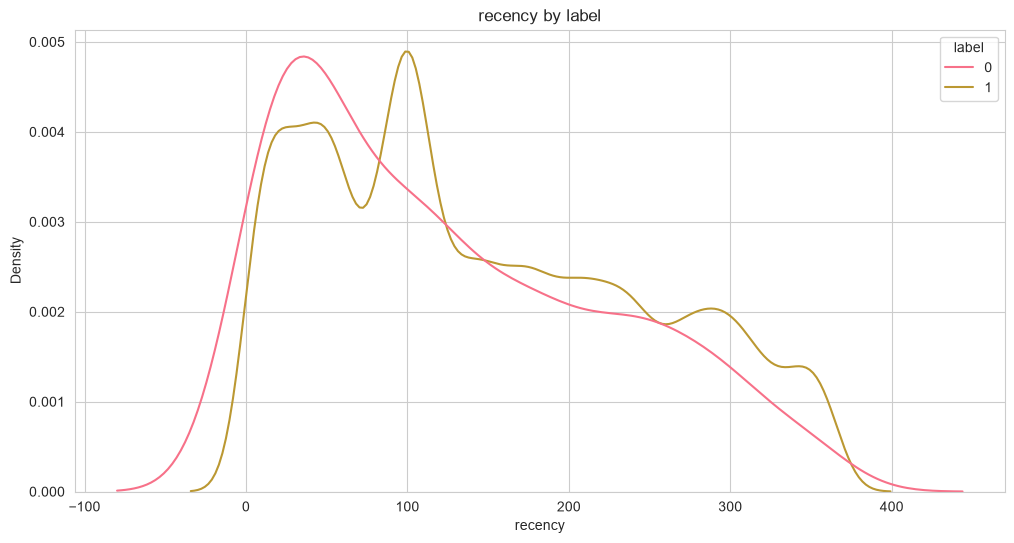

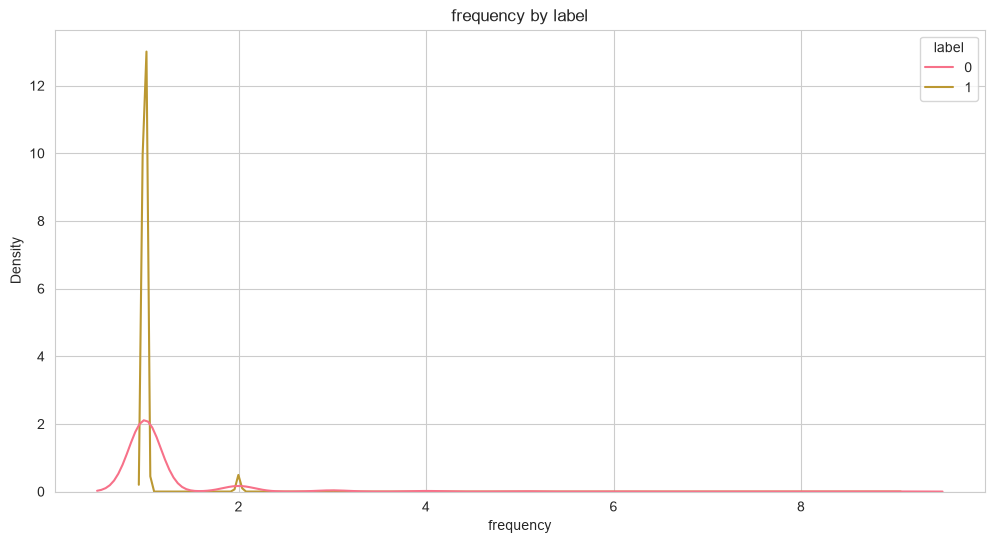

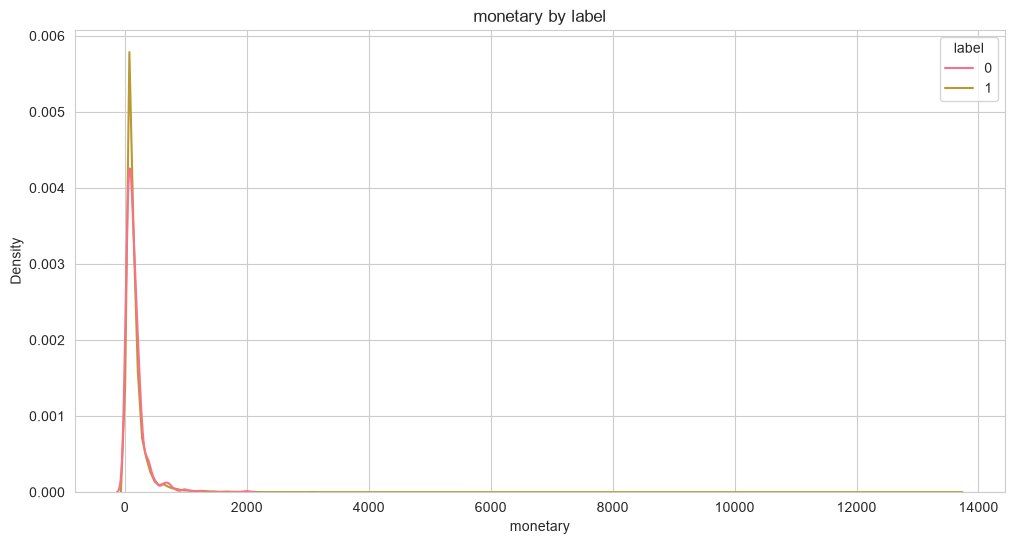

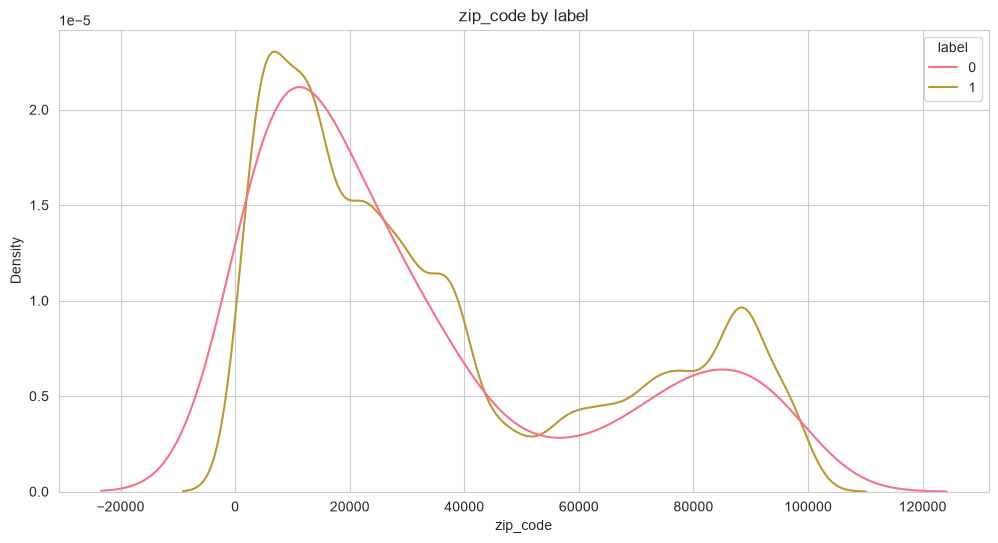

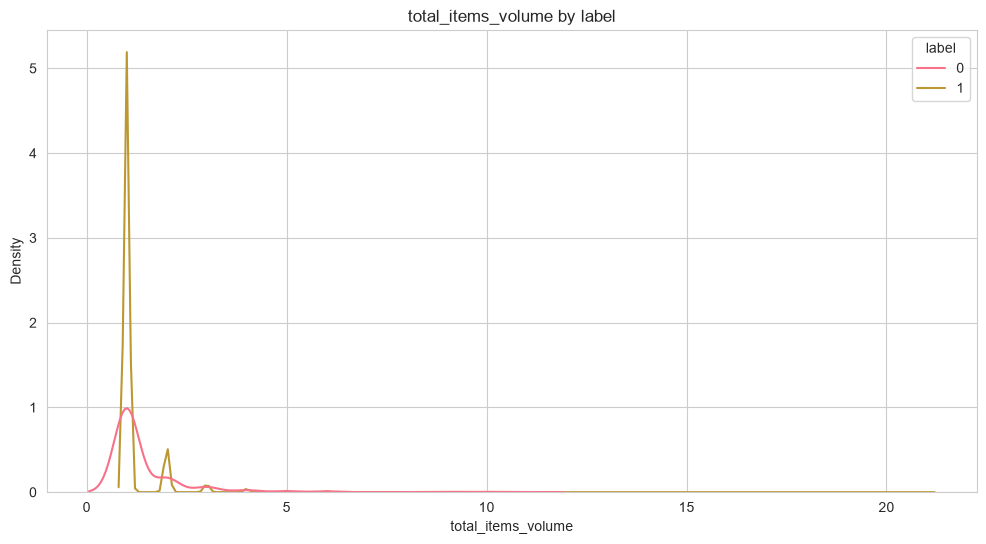

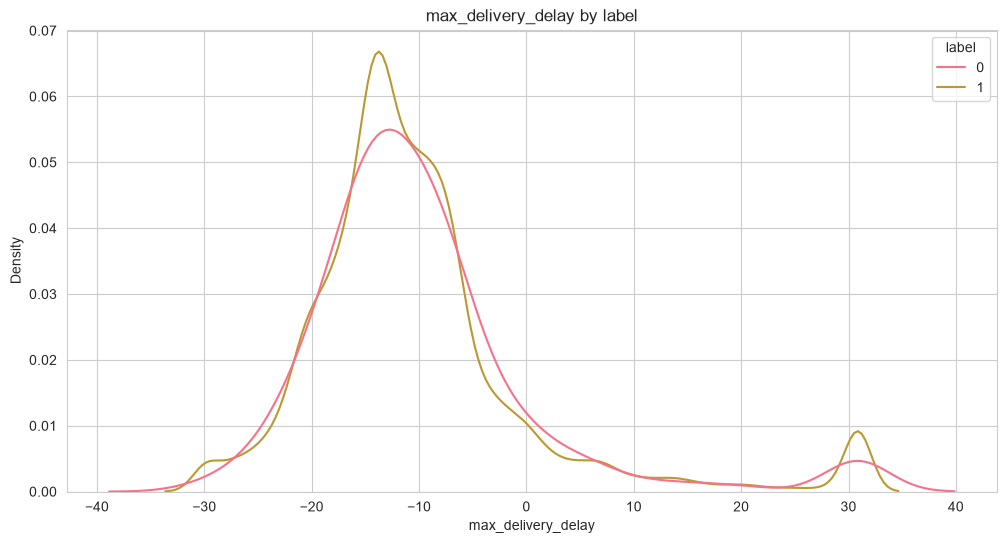

In [40]:
TARGET = "label"  # <-- set this

if df[TARGET].dtype == 'object' or df[TARGET].nunique() <= 20:
    # Classification
    vc = df[TARGET].value_counts()
    print(vc)
    print(f"\nImbalance ratio: {vc.iloc[0]/vc.iloc[-1]:.2f}")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    vc.plot(kind='bar', ax=ax[0], color='steelblue')
    ax[0].set_title('Target distribution')
    vc.plot(kind='pie', ax=ax[1], autopct='%1.1f%%')
    ax[1].set_ylabel('')
    ax[1].set_title('Target proportion')
    plt.tight_layout()
    plt.show()

    # Feature vs target
    for col in num_cols[:6]:
        sns.kdeplot(data=df, x=col, hue=TARGET, common_norm=False)
        plt.title(f'{col} by {TARGET}')
        plt.show()
else:
    # Regression
    print(df[TARGET].describe())
    sns.histplot(df[TARGET].dropna(), kde=True, bins=30)
    plt.title(f'Target: {TARGET}')
    plt.show()

    corr_target = df[num_cols].corrwith(df[TARGET]).sort_values(key=abs, ascending=False)
    print("\nTop correlations with target:")
    print(corr_target.head(15))

##Time Series

In [ ]:
for dt in dt_cols[:2]:
    ts = df.set_index(dt).sort_index()
    for num in num_cols[:3]:
        ts[num].resample('D').mean().plot(figsize=(12, 4))
        plt.title(f'{num} over time (daily mean)')
        plt.tight_layout()
        plt.show()